# 9.5 Statistical Computing

**Goal:** distinguish random-number generation, Monte Carlo error, MCMC dependence, and variational approximation.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Information Theory](1_Information-Theory.ipynb)
2. [Statistical Learning Theory](2_Statistical-Learning-Theory.ipynb)
3. [Advanced Probability](3_Advanced-Probability.ipynb)
4. [Time-Series Statistics](4_Time-Series-Statistics.ipynb)
5. [Statistical Computing](5_Statistical-Computing.ipynb)
6. [Specialized Statistical Methods](6_Specialized-Statistical-Methods.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Random Number Generation and Monte Carlo Methods

Pseudorandom generators deterministically transform a seed/state into a stream approximating a desired random mechanism. Use local generator objects for reproducibility and independent spawned streams for parallel simulations. A fixed seed is not a mathematical proof of independence, statistical validity, or cryptographic security.

Monte Carlo estimates $E[h(X)]$ by sample averages; under IID finite-variance sampling its MC SE is SD(h)/√B. Importance sampling changes proposal distributions and uses weights, requiring support coverage and potentially finite weight variance. Rare extreme weights can make estimates unstable. Monte Carlo error is distinct from uncertainty in the fitted model or original data.

In [2]:
u=rng.random(20000);integrand=np.exp(-u*u)
print("MC integral on [0,1]:",integrand.mean(),"MC SE:",integrand.std(ddof=1)/np.sqrt(len(u)))
from scipy.integrate import quad
exact,_=quad(lambda x:np.exp(-x*x),0,1)
print("Quadrature reference:",exact)

MC integral on [0,1]: 0.7463687557193213 MC SE: 0.001419096991973265
Quadrature reference: 0.7468241328124271


## 2. Numerical Integration

Quadrature approximates an integral using function evaluations and weights, often more efficient than generic Monte Carlo in low dimension. Trapezoidal/Simpson methods depend on grid spacing and smoothness; adaptive quadrature targets local error. Report numerical tolerances and compare refinements where possible. A numerical error estimate is not a confidence interval for the scientific model.

High-dimensional integrals, discontinuities, singular endpoints, and extreme tails require specialized strategies. Normalization integrals can also be expensive or unavailable, motivating MCMC and variational methods.

## 3. Markov Chain Monte Carlo (MCMC) and Metropolis–Hastings Algorithm

MCMC builds a dependent chain with the desired invariant distribution. Metropolis–Hastings proposes x′ from q(x′|x) and accepts with probability min(1,π(x′)q(x|x′)/[π(x)q(x′|x)]). A symmetric random-walk proposal cancels q; compute log ratios for stability. Unknown target normalization cancels, but the target must still define a proper distribution.

Convergence requires more than an invariant density: irreducibility, aperiodicity, and suitable recurrence/ergodicity conditions matter. Poor proposal scales can cause tiny steps or many rejections. Discarding burn-in does not prove convergence; assess multiple dispersed chains, traces, autocorrelation, effective sample sizes, and suitable R-hat diagnostics.

**Worked example:** a random-walk chain targets a standard normal. Its stored values are correlated, so n samples do not automatically have the precision of n independent normal draws.

MH mean/variance: 0.02185188506745576 0.9862670917121759 acceptance: 0.7112259354946245


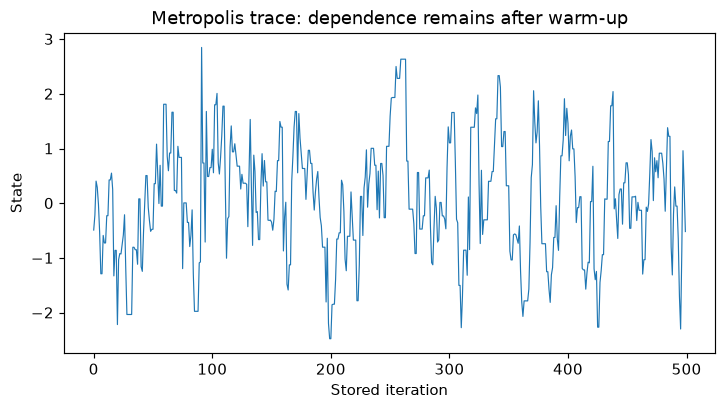

In [3]:
B=12000;chain=np.zeros(B);accepted=0
for i in range(1,B):
    proposal=chain[i-1]+rng.normal(scale=1.)
    log_ratio=-.5*(proposal**2-chain[i-1]**2)
    if np.log(rng.random())<min(0.,log_ratio):chain[i]=proposal;accepted+=1
    else:chain[i]=chain[i-1]
post=chain[2000:]
print("MH mean/variance:",post.mean(),post.var(),"acceptance:",accepted/(B-1))
fig,ax=plt.subplots();ax.plot(post[:500],linewidth=.8)
ax.set(title="Metropolis trace: dependence remains after warm-up",xlabel="Stored iteration",ylabel="State");fig.tight_layout();plt.show()

## 4. Gibbs Sampling

Gibbs updates each block from its full conditional, which yields an invariant joint distribution under suitable conditions. Conditional sampling is not equivalent to sampling each marginal independently. Strong dependence can slow mixing, and disconnected conditionals can trap a chain.

**Example:** for a zero-mean bivariate normal with unit marginal variances and correlation ρ, X|Y=y∼Normal(ρy,1−ρ²), followed by Y|X=x using the newly updated x. The resulting stationary joint correlation is ρ, unlike independent marginal sampling.

In [4]:
rho=.8;gibbs=np.zeros((10000,2));conditional_sd=np.sqrt(1-rho*rho)
for i in range(1,len(gibbs)):
    gibbs[i,0]=rng.normal(rho*gibbs[i-1,1],conditional_sd)
    gibbs[i,1]=rng.normal(rho*gibbs[i,0],conditional_sd)
print("Gibbs post-warm-up correlation:",np.corrcoef(gibbs[2000:].T)[0,1])

Gibbs post-warm-up correlation: 0.8012767551947284


## 5. Variational Inference

Variational inference approximates a posterior with a tractable q by maximizing ELBO or minimizing KL(q||posterior). It replaces sampling error with optimization and approximation error, though stochastic optimization can add Monte Carlo noise. A high ELBO relative to one candidate does not prove exact inference or calibrated uncertainty.

**Mean-field example:** approximate a correlated zero-mean Gaussian with unit marginal variances and correlation ρ by independent normal components. The optimal reverse-KL diagonal variances are 1−ρ², smaller than the true marginal variances 1. The factorization cannot reproduce correlation, and can underestimate uncertainty even with perfect optimization. Richer families help but require additional computation and diagnostics.

In [5]:
Sigma=np.array([[1.,rho],[rho,1.]])
q_cov=(1-rho*rho)*np.eye(2)
kl=.5*(np.trace(np.linalg.solve(Sigma,q_cov))-2+np.linalg.slogdet(Sigma)[1]-np.linalg.slogdet(q_cov)[1])
print("True marginal variances:",np.diag(Sigma),"mean-field variances:",np.diag(q_cov),"KL:",kl)
assert kl>=0

True marginal variances: [1. 1.] mean-field variances: [0.36 0.36] KL: 0.5108256237659906


## AI/ML application and interpretation

Statistical computing powers Bayesian inference, probabilistic programming, latent-variable models, and generative ML. Validate on known-answer problems, compare independent runs, and distinguish numerical convergence from model adequacy. Neither MCMC nor variational inference repairs a misspecified likelihood or biased dataset.

## Practice

1. What uncertainty does a Monte Carlo SE quantify?
2. Why does symmetric-proposal MH omit proposal-density factors?
3. Does removing 1000 iterations certify MCMC convergence?
4. Can a fully optimized mean-field approximation still miss posterior uncertainty?

## Solutions

1. Random numerical integration variability under its simulation assumptions, not every source of model/data uncertainty.
2. Forward and reverse proposal densities cancel in the acceptance ratio.
3. No. Warm-up is a practice requiring diagnostics, not a universal proof.
4. Yes. Restrictions such as independence can miss covariance, tails, and modes even at the exact variational optimum.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](6_Specialized-Statistical-Methods.ipynb).